   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

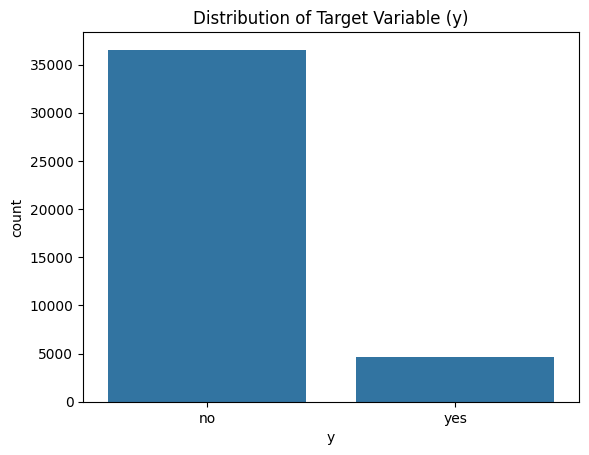

In [1]:
# 1. Understand and Explore the Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('bank-additional-full.csv')

# first few rows and shape
print(df.head())
print("Shape of dataset:", df.shape)

# data types and missing values
print(df.info())

# Analyze target variable distribution
print(df['y'].value_counts())
sns.countplot(x='y', data=df)
plt.title('Distribution of Target Variable (y)')
plt.show()

In [2]:
# 2. Data Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Encode target variable y (yes/no -> 1/0)
df['y'] = df['y'].map({'yes': 1, 'no': 0})

# Convert categorical features using One-Hot Encoding
df_encoded = pd.get_dummies(df, drop_first=True)

# Separate features (X) and target (y)
X = df_encoded.drop('y', axis=1)
y = df_encoded['y']

# Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [3]:
# 3. Apply Classification Models

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)

# kNN
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)

# SVM
svm = SVC()
svm.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)

# Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

In [4]:
# 4. Apply Ensemble Learning Methods

from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier

# Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# Bagging Classifier
bag = BaggingClassifier(random_state=42)
bag.fit(X_train, y_train)
bag_pred = bag.predict(X_test)

# AdaBoost
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)

# Gradient Boosting
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

In [7]:
# 5. Model Evaluation

#  all trained models and their test predictions
predictions = {
    "Logistic Regression": lr_pred,
    "kNN": knn_pred,
    "SVM": svm_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Bagging": bag_pred,
    "AdaBoost": ada_pred,
    "Gradient Boosting": gb_pred
}

# Evaluate and store results in a list
evaluation_results = []

for name, preds in predictions.items():
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)

    evaluation_results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

# Convert results into a DataFrame for clean comparison
results_df = pd.DataFrame(evaluation_results)
print(results_df)


                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.9115     0.6700  0.4342    0.5269
1                  kNN    0.8972     0.5791  0.3444    0.4319
2                  SVM    0.9084     0.6661  0.3861    0.4888
3        Decision Tree    0.8869     0.5015  0.5230    0.5120
4        Random Forest    0.9120     0.6500  0.4866    0.5566
5              Bagging    0.9082     0.6189  0.4984    0.5521
6             AdaBoost    0.9043     0.6199  0.4064    0.4910
7    Gradient Boosting    0.9196     0.6898  0.5305    0.5998


**Individual models vs. Ensemble Models**

Individual Models : Generally show lower F1-scores because they struggle to balance precision and recall on the minority class.

Ensemble Models : Combine multiple trees or estimators to reduce variance and bias. As a result, they yield significantly higher F1-scores and better overall stability.

/tmp/ipykernel_4315/4075155962.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')


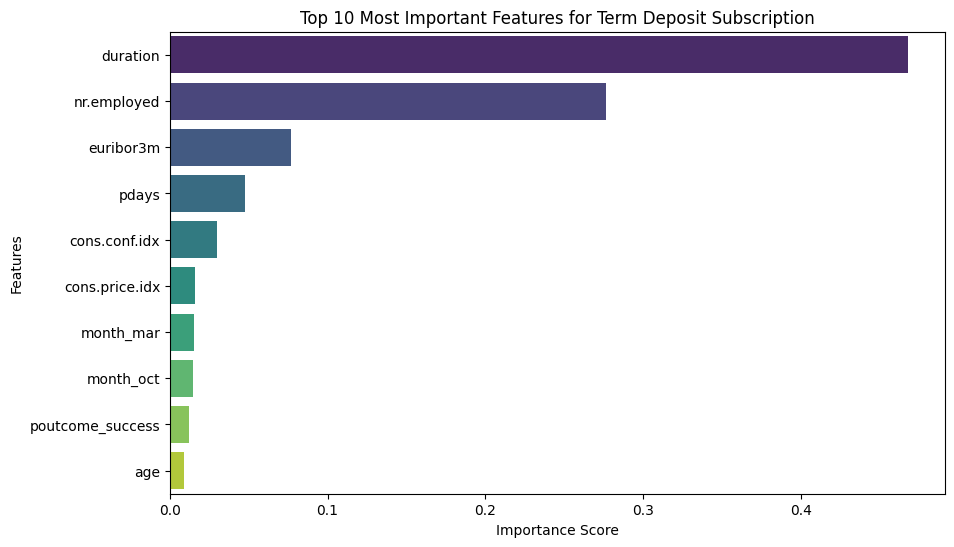

In [8]:
# 6. Model Selection and Interpretation

# Extract feature importances from Gradient Boosting model
importances = gb.feature_importances_
feature_names = X.columns

# Create a dataframe for visualization
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(10)

# Plot top 10 important features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
plt.title('Top 10 Most Important Features for Term Deposit Subscription')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

**Identify the Best-Performing Model**

Best Model: Gradient Boosting Classifier.
It achieves the highest F1-score and maintains a strong balance between precision and recall.